# 05 · LightGBM directo frente a reglas simples

Entrenamos cuatro modelos globales por objetivo: t+1, t+2, t+3 y t+4.
El test tiene las mismas fechas, universo y segmentos del notebook 04.
La validación reserva ocho semanas de origen dentro de train, con su propio
hueco de cuatro semanas. El test no participa del entrenamiento ni del early stopping.

Este notebook se ejecuta desde `notebooks/`, con Python 3.11 y el entorno `stockifai`.
Las funciones usan la API `eval_X`/`eval_y` de LightGBM 4.7.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
sys.path.append("../src")

import os
from pathlib import Path
from importlib.metadata import version

# MLflow 3.17 requiere habilitar explícitamente el tracking en archivos.
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"
import mlflow
import mlflow.lightgbm
from mlflow.models import infer_signature
import numpy as np
import pandas as pd
from io import BytesIO
from matplotlib.figure import Figure
from IPython.display import display, Image

from stockifai_forecast.datos import leer_movimientos, agregar_semanal, rellenar_ceros
from stockifai_forecast.features import construir_abt
from stockifai_forecast.evaluacion import dividir_por_fecha, etiquetar_con_train, evaluar_baselines
from stockifai_forecast.modelado import (
    columnas_features, separar_validacion, entrenar_modelos, predecir, evaluar_modelo,
)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
raiz_repo = Path("..").resolve()
mlflow.set_tracking_uri((raiz_repo / "mlruns").as_uri())
mlflow.set_experiment("stockifai_comparacion_directa")
versiones = {paquete: version(paquete) for paquete in
             ["lightgbm", "mlflow", "pandas", "numpy", "scikit-learn"]}
print("Versiones:", versiones)
print("Tracking local:", mlflow.get_tracking_uri())

Versiones: {'lightgbm': '4.7.0', 'mlflow': '3.17.0', 'pandas': '3.0.6', 'numpy': '2.4.6', 'scikit-learn': '1.9.1'}
Tracking local: file:///C:/Users/Usuario/Documents/Codex/2026-11-02/referenced-chatgpt-conversation-this-is-an/outputs/stockifai-lightgbm/mlruns


## 1. Datos y cortes temporales

Cada fila usa información disponible al cerrar t. Los objetivos son ventas
futuras; para entrenar exigimos que las cuatro respuestas sean anteriores al
siguiente corte. Las filas del final sin respuestas no se evalúan.


In [3]:
mov = leer_movimientos("../data/raw/Import-Movimientos.xlsx")
semanal = agregar_semanal(mov)
serie = rellenar_ceros(semanal)
abt = construir_abt(serie)
partes = dividir_por_fecha(abt)
internas = separar_validacion(partes["train"])
inicio_test, inicio_val = partes["inicio_test"], internas["inicio_val"]
print(f"Inicio de validación: {inicio_val:%Y-%m-%d}")
print(f"Inicio de test: {inicio_test:%Y-%m-%d}")

assert (internas["fit"]["semana"] + pd.Timedelta(weeks=4) < inicio_val).all()
assert (partes["train"]["semana"] + pd.Timedelta(weeks=4) < inicio_test).all()
for tabla in (internas["fit"], internas["val"]):
    assert tabla.index.intersection(partes["test"].index).empty
display(pd.DataFrame([
    {"parte": nombre, "filas antes de universo": len(tabla),
     "desde": tabla["semana"].min(), "hasta": tabla["semana"].max(),
     "semanas de origen": tabla["semana"].nunique()}
    for nombre, tabla in [("fit", internas["fit"]), ("val", internas["val"]), ("test", partes["test"])]
]))

Inicio de validación: 2024-11-04
Inicio de test: 2025-01-27


,parte,filas antes de universo,desde,hasta,semanas de origen
0,fit,460056,2020-08-10,2024-09-30,217
1,val,28910,2024-11-04,2024-12-23,8
2,test,83396,2025-01-27,2025-06-23,22


## 2. Etiquetas disponibles en cada momento

Para el early stopping, universo y segmento se calculan antes de **inicio_val**.
Usar las etiquetas de todo train anticiparía ventas de validación. Para evaluar
test, mantenemos las etiquetas anteriores a **inicio_test** del notebook 04.
Un modelo global puede predecir repuestos que aún no eran elegibles en fit.

Los modelos se ajustan en fit y se detienen con val; no hacemos un reajuste final
con todo train. Conservamos los índices originales al unir las fichas para
poder comprobar que test, fit y val no se solapan.


In [4]:
etiquetas_internas = etiquetar_con_train(serie, inicio_val).set_index("repuesto")
etiquetas_test = etiquetar_con_train(serie, inicio_test).set_index("repuesto")
fit = internas["fit"].join(etiquetas_internas, on="repuesto", validate="many_to_one")
val = internas["val"].join(etiquetas_internas, on="repuesto", validate="many_to_one")
test_etiquetado = partes["test"].join(etiquetas_test, on="repuesto", validate="many_to_one")

fit_usado = fit.loc[fit["entra_modelo"].eq(True).fillna(False)]
val_usado = val.loc[val["entra_modelo"].eq(True).fillna(False)]
test_usado = test_etiquetado.loc[test_etiquetado["entra_modelo"].eq(True).fillna(False)]
features = columnas_features(fit)
display(pd.DataFrame([
    {"parte": nombre, "filas del universo": len(tabla), "repuestos": tabla["repuesto"].nunique()}
    for nombre, tabla in [("fit", fit_usado), ("val", val_usado), ("test", test_usado)]
]))
print("Features:", features)
assert len(features) == 17
assert not set(features) & {"repuesto", "semana", "grupo_historia", "entra_modelo"}

Features: ['cantidad', 'lag_1', 'lag_2', 'lag_3', 'prom_4', 'prom_8', 'prom_12', 'desvio_8', 'semanas_con_venta_8', 'semanas_desde_ultima_venta', 'mes', 'semana_del_anio', 'feriados_t1', 'feriados_t2', 'feriados_t3', 'feriados_t4', 'segmento']


,parte,filas del universo,repuestos
0,fit,83760,435
1,val,3480,435
2,test,10032,456


## 3. Tracking local y baselines

MLflow es el cuaderno de experimentos: un run para los baselines y uno para cada
objetivo. Guarda parámetros, errores, cantidades de filas, mejores iteraciones
y modelos. Todo queda en `../mlruns/`, ignorado por Git. El registro no envía datos
a un servidor externo. Volver a ejecutar crea otros tres runs, sin borrar los anteriores.


In [5]:
parametros_comunes = {
    "horizonte": 4, "semanas_test": 26, "semanas_val": 8, "hueco_semanas": 4,
    "inicio_test": str(inicio_test.date()), "inicio_val": str(inicio_val.date()),
    "min_semanas_con_venta": 10, "umbral_frecuencia": 0.25,
    "filas_fit": len(fit_usado), "filas_val": len(val_usado), "filas_test": len(test_usado),
    "corte_etiquetas_fit_val": str(inicio_val.date()),
    "corte_etiquetas_test": str(inicio_test.date()),
    "features": ",".join(features), "python": sys.version.split()[0],
    **{f"version_{k}": v for k, v in versiones.items()},
}

def registrar_metricas(metricas, prefijo="test"):
    valores = {}
    for fila in metricas.itertuples(index=False):
        grupo = str(fila.grupo).replace("+", "_mas")
        base = f"{prefijo}/{fila.baseline}/{fila.agrupacion}/{grupo}/h{fila.horizonte}"
        for campo in ["mae", "n_candidatas", "n_filas", "n_excluidas", "n_sin_target"]:
            valor = getattr(fila, campo)
            if pd.notna(valor):
                valores[f"{base}/{campo}"] = float(valor)
    mlflow.log_metrics(valores)
    mlflow.log_text(metricas.to_csv(index=False), "metricas_test.csv")

baselines = evaluar_baselines(test_etiquetado)
run_ids = {}
with mlflow.start_run(run_name="baselines") as run:
    run_ids["baselines"] = run.info.run_id
    mlflow.log_params({**parametros_comunes, "reglas": "cero,prom_8"})
    registrar_metricas(baselines)
display(baselines.loc[baselines["agrupacion"] == "total"].round(4))

,baseline,horizonte,agrupacion,grupo,mae,n_candidatas,n_filas,n_excluidas,n_sin_target
0,cero,1,total,total,0.7142,10032,10032,0,0
1,prom_8,1,total,total,0.3808,10032,10032,0,0
10,cero,2,total,total,0.7048,10032,10032,0,0
11,prom_8,2,total,total,0.3835,10032,10032,0,0
20,cero,3,total,total,0.7071,10032,10032,0,0
21,prom_8,3,total,total,0.3931,10032,10032,0,0
30,cero,4,total,total,0.7035,10032,10032,0,0
31,prom_8,4,total,total,0.4022,10032,10032,0,0


## 4. Entrenar L1 y Tweedie

**L1** penaliza el error absoluto y tiende a aprender una mediana condicional.
Con muchas semanas en cero, una mediana puede ser cero.
**Tweedie (potencia 1,5)** permite ceros y valores positivos: se puede imaginar
una suma de compras, donde algunas semanas no llega ninguna. Aprende una media
no negativa; no es un clasificador «vende/no vende» ni exige predicciones enteras.

Cada modelo tiene como máximo 2.000 árboles y agrega correcciones pequeñas
(`learning_rate=0.05`). El early stopping observa solamente MAE de val, con
100 rondas de paciencia. La mejor iteración se conserva para predecir.
`segmento` es categórica, con el mismo diccionario en fit, val e inferencia.


In [6]:
modelos_por_objetivo = {}
predicciones_por_objetivo = {}
metricas_por_objetivo = {}
mejores = []
referencia_filas = baselines.loc[baselines["baseline"] == "cero"].set_index(
    ["horizonte", "agrupacion", "grupo"])["n_filas"].sort_index()

ejemplo = fit_usado[features].head(5).copy()
ejemplo["segmento"] = pd.Categorical(ejemplo["segmento"],
                                     categories=["frecuencia_alta", "intermitente"])
ejemplo = ejemplo.astype({c: "float64" for c in features if c != "segmento"})
requisitos = [f"{k}=={v}" for k, v in versiones.items()]

for objetivo in ["l1", "tweedie"]:
    print(f"Entrenando {objetivo}...", flush=True)
    with mlflow.start_run(run_name=f"lightgbm_{objetivo}") as run:
        run_ids[objetivo] = run.info.run_id
        mlflow.log_params({**parametros_comunes, "objective": objetivo, "metric": "l1",
                           "learning_rate": 0.05, "n_estimators": 2000,
                           "early_stopping_rounds": 100, "semilla": 42,
                           "predicciones_recortadas_a_cero": True})
        if objetivo == "tweedie":
            mlflow.log_param("tweedie_variance_power", 1.5)
        modelos = entrenar_modelos(fit, val, features, objetivo)
        mlflow.log_dict(modelos[1].get_params(), "hiperparametros.json")
        modelos_por_objetivo[objetivo] = modelos
        # Solo predecimos las filas evaluables del universo; expandimos al índice
        # completo de test para que evaluar_modelo verifique todas las claves.
        predicciones = predecir(modelos, test_usado, features).reindex(test_etiquetado.index)
        predicciones_por_objetivo[objetivo] = predicciones
        metricas = evaluar_modelo(test_etiquetado, predicciones, f"LightGBM {objetivo}")
        metricas_por_objetivo[objetivo] = metricas
        filas_modelo = metricas.set_index(["horizonte", "agrupacion", "grupo"])["n_filas"].sort_index()
        pd.testing.assert_series_equal(filas_modelo, referencia_filas)
        registrar_metricas(metricas)
        for h, modelo in modelos.items():
            mae_val = modelo.best_score_["valid_0"]["l1"]
            mejores.append({"objetivo": objetivo, "horizonte": h,
                            "mejor_iteracion": modelo.best_iteration_, "mae_val": mae_val})
            mlflow.log_metrics({f"mejor_iteracion/h{h}": modelo.best_iteration_,
                                f"validacion/mae_h{h}": mae_val})
            firma = infer_signature(ejemplo, modelo.predict(ejemplo))
            mlflow.lightgbm.log_model(modelo, name=f"modelo_h{h}", signature=firma,
                                      pip_requirements=requisitos,
                                      metadata={"horizonte": h, "clip_inferencia": ">=0 con predecir"})
            print(f"{objetivo} t+{h}: iteración {modelo.best_iteration_}, MAE val {mae_val:.4f}", flush=True)

mejores_iteraciones = pd.DataFrame(mejores)
display(mejores_iteraciones.round(4))

Entrenando l1...
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003210 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1749
[LightGBM] [Info] Number of data points in the train set: 83760, number of used features: 17
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003164 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1749
[LightGBM] [Info] Number of data points in the train set: 83760, number of used features: 17
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.003346 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1749
[LightGBM] [Info]

,objetivo,horizonte,mejor_iteracion,mae_val
0,l1,1,316,0.4281
1,l1,2,185,0.4441
2,l1,3,236,0.4694
3,l1,4,115,0.4442
4,tweedie,1,830,0.4864
5,tweedie,2,863,0.5012
6,tweedie,3,224,0.5386
7,tweedie,4,311,0.5219


## 5. Comparación sobre exactamente el mismo test

La comparación con cero y prom_8 usa las mismas 10.032 filas por horizonte del
notebook 04. Si faltara un promedio, la aserción de cobertura de abajo impediría
presentar como equivalentes dos resultados con filas distintas.
Menor MAE es mejor; el resumen promedia los cuatro horizontes con el mismo peso.
Cada columna marca todos los empates en su mínimo.


In [7]:
metricas = pd.concat([baselines, *metricas_por_objetivo.values()], ignore_index=True)
filas_promedio = baselines.loc[baselines["baseline"] == "prom_8"].set_index(
    ["horizonte", "agrupacion", "grupo"])["n_filas"].sort_index()
pd.testing.assert_series_equal(filas_promedio, referencia_filas)

orden = ["cero", "prom_8", "LightGBM l1", "LightGBM tweedie"]
nombres = {"cero": "Predecir 0", "prom_8": "prom_8"}
columnas = [("segmento", "intermitente"), ("segmento", "frecuencia_alta"),
            ("grupo_historia", "10-25"), ("grupo_historia", "26+"), ("total", "total")]
resumen = (metricas.groupby(["baseline", "agrupacion", "grupo"])["mae"].mean()
           .unstack(["agrupacion", "grupo"]).reindex(index=orden, columns=columnas))
resumen.columns = ["Intermitentes", "Frecuencia alta", "Historia 10-25", "Historia 26+", "Total"]
resumen = resumen.rename(index=nombres)
display(resumen.style.format("{:.4f}").highlight_min(axis=0))
ganadores = resumen.apply(lambda c: ", ".join(c.index[np.isclose(c, c.min(), rtol=0, atol=1e-10)]))
display(ganadores.rename("Ganador por MAE").to_frame())

tablas_horizonte = {}
for h in range(1, 5):
    tabla = (metricas.loc[metricas["horizonte"] == h]
             .pivot(index="baseline", columns=["agrupacion", "grupo"], values="mae")
             .reindex(index=orden, columns=columnas).rename(index=nombres))
    tabla.columns = resumen.columns
    tablas_horizonte[h] = tabla
    print(f"Horizonte t+{h}")
    display(tabla.style.format("{:.4f}").highlight_min(axis=0))

Horizonte t+1
Horizonte t+2
Horizonte t+3
Horizonte t+4


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
Predecir 0,0.0800,3.1235,0.0562,1.5048,0.7074
prom_8,0.1392,1.3554,0.1006,0.7442,0.3899
LightGBM l1,0.0804,1.1631,0.0564,0.6063,0.3036
LightGBM tweedie,0.1574,1.3308,0.1272,0.7325,0.3993


,Ganador por MAE
Intermitentes,Predecir 0
Frecuencia alta,LightGBM l1
Historia 10-25,Predecir 0
Historia 26+,LightGBM l1
Total,LightGBM l1


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
Predecir 0,0.0786,3.1620,0.0545,1.5220,0.7142
prom_8,0.1385,1.3140,0.1003,0.7243,0.3808
LightGBM l1,0.0791,1.1335,0.0544,0.5929,0.2965
LightGBM tweedie,0.1523,1.2705,0.1214,0.7029,0.3828


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
Predecir 0,0.0791,3.1146,0.0556,1.4998,0.7048
prom_8,0.1389,1.3256,0.1005,0.7300,0.3835
LightGBM l1,0.0795,1.1483,0.0560,0.5983,0.2998
LightGBM tweedie,0.1511,1.2352,0.1211,0.6849,0.3746


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
Predecir 0,0.0799,3.1228,0.0570,1.5031,0.7071
prom_8,0.1383,1.3744,0.0998,0.7522,0.3931
LightGBM l1,0.0803,1.1792,0.0572,0.6124,0.3068
LightGBM tweedie,0.1615,1.3854,0.1323,0.7586,0.4138


,Intermitentes,Frecuencia alta,Historia 10-25,Historia 26+,Total
baseline,,,,,
Predecir 0,0.0826,3.0948,0.0578,1.4942,0.7035
prom_8,0.1410,1.4079,0.1016,0.7701,0.4022
LightGBM l1,0.0829,1.1912,0.0579,0.6217,0.3113
LightGBM tweedie,0.1648,1.4320,0.1340,0.7835,0.4260


## 6. Variables importantes de t+1

Elegimos el objetivo de t+1 por menor MAE en validación, antes de mirar el test.
La importancia **gain** suma cuánto ayudaron los cortes de cada variable a
mejorar el objetivo durante el entrenamiento. No es una relación causal ni un
porcentaje de precisión. Las escalas de gain de L1 y Tweedie no son comparables.


Objetivo elegido por validación para t+1: l1


,feature,gain
6,prom_12,92706.513342
8,semanas_con_venta_8,77276.157440
0,cantidad,39294.975935
16,segmento,33985.982950
9,semanas_desde_ultima_venta,13009.380321
4,prom_4,8693.106846
5,prom_8,6248.571222
1,lag_1,5630.989173
11,semana_del_anio,5274.329135
7,desvio_8,4517.990945


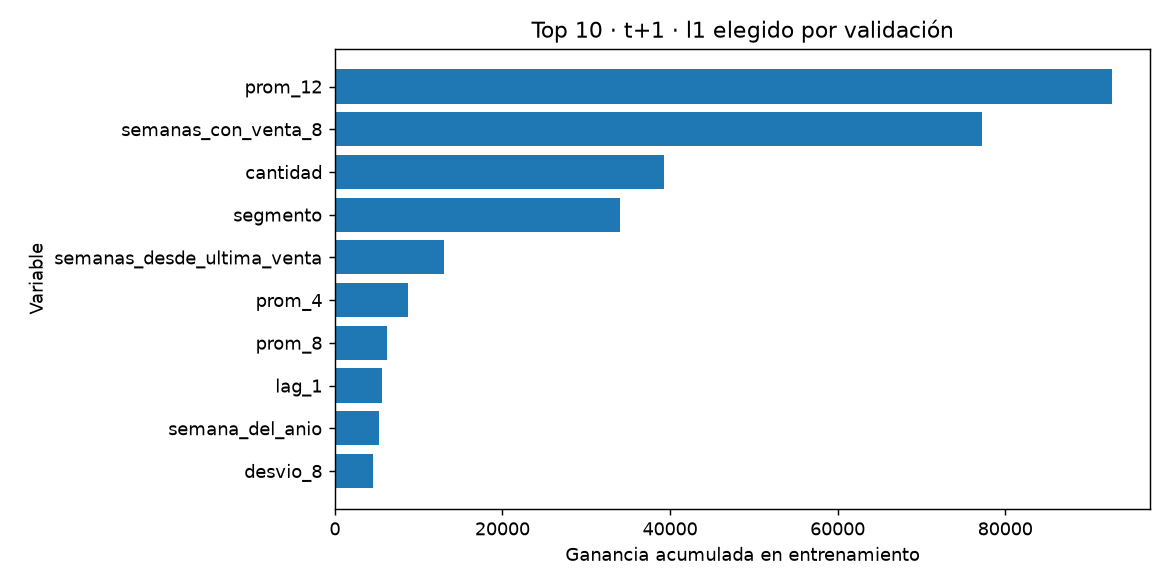

In [8]:
mejor_objetivo_t1 = (mejores_iteraciones.loc[mejores_iteraciones["horizonte"] == 1]
                     .sort_values(["mae_val", "objetivo"]).iloc[0]["objetivo"])
mejor_t1 = modelos_por_objetivo[mejor_objetivo_t1][1]
importancias = pd.DataFrame({
    "feature": mejor_t1.feature_name_,
    "gain": mejor_t1.booster_.feature_importance(importance_type="gain"),
}).sort_values("gain", ascending=False).head(10)
print("Objetivo elegido por validación para t+1:", mejor_objetivo_t1)
display(importancias)
fig = Figure(figsize=(9, 4.5))
ax = fig.subplots()
ax.barh(importancias.iloc[::-1]["feature"], importancias.iloc[::-1]["gain"])
ax.set_xlabel("Ganancia acumulada en entrenamiento")
ax.set_ylabel("Variable")
ax.set_title(f"Top 10 · t+1 · {mejor_objetivo_t1} elegido por validación")
fig.tight_layout()
buffer_figura = BytesIO()
fig.savefig(buffer_figura, format="png", dpi=130)
display(Image(data=buffer_figura.getvalue()))

## 7. Comprobar los registros y poder recuperarlos

El siguiente control verifica los tres runs y los cuatro modelos por objetivo,
y carga un modelo guardado para comprobar que reproduce sus predicciones.
MLflow guarda los modelos sin el recorte externo; para usar la regla completa
se llama a `predecir`, que recorta los valores negativos a cero.


In [9]:
cliente = mlflow.tracking.MlflowClient()
for nombre, run_id in run_ids.items():
    run = cliente.get_run(run_id)
    assert run.info.status == "FINISHED"
    print(nombre, run_id, "métricas:", len(run.data.metrics))
for objetivo in ["l1", "tweedie"]:
    run_id = run_ids[objetivo]
    for h in range(1, 5):
        recuperado = mlflow.lightgbm.load_model(f"runs:/{run_id}/modelo_h{h}")
        np.testing.assert_allclose(recuperado.predict(ejemplo),
                                   modelos_por_objetivo[objetivo][h].predict(ejemplo))
print("OK: ocho modelos registrados y recuperados sin cambiar sus predicciones.")

baselines 6e369099ca0641a6beb8bfd5f587f34e métricas: 200
l1 97430259a5994cccb366eed719655541 métricas: 108
tweedie d11db3f7d45f44189c6e99b41deb5e6a métricas: 108
OK: ocho modelos registrados y recuperados sin cambiar sus predicciones.


## Cómo leer las funciones y los parámetros

- `columnas_features`: lista blanca de 16 variables más segmento. Aunque aparezca
  una columna nueva o un target, no entra automáticamente al modelo.
- `separar_validacion`: si val empieza en la semana 100, fit solo llega a la 95;
  las filas 96–99 no pueden aportar respuestas a val.
- `entrenar_modelos`: elimina filas fuera del universo, convierte segmento en
  categoría y aprende una función para cada target. No recibe test como argumento.
- `predecir`: aplica los modelos conservando el índice de las filas y convierte
  una predicción negativa, por ejemplo −0,2, en 0.
- `evaluar_modelo`: alinea por índice, exige todas las predicciones evaluables y
  reutiliza los grupos y el cálculo de MAE de `evaluar_baselines`.

**Métodos y parámetros nuevos**

- `pd.Categorical`: diccionario estable de etiquetas, sin asignarles un orden numérico.
  `categorical_feature=["segmento"]` indica a LightGBM que trate esos valores como categorías.
- `learning_rate`: tamaño de cada corrección; `n_estimators`, máximo de árboles.
  `random_state` fija la semilla para repetir el experimento en el mismo entorno.
- `objective` indica qué aprende a minimizar el modelo. `metric="l1"` fija el
  criterio de validación también para Tweedie: ambos se frenan según MAE.
- `early_stopping(100)`: guarda la mejor iteración y deja de agregar árboles
  tras cien rondas sin mejora de validación. `best_iteration_` informa esa ronda.
- `.join(..., on="repuesto")`: como un LEFT JOIN de SQL que conserva el índice
  semanal. `.reindex(...)` alinea predicciones por su identificador de fila.
- `np.maximum(pred, 0)` hace lo mismo que `MAX(predicción; 0)` en Excel.
- `.style.highlight_min(axis=0)` marca el menor valor en cada columna, como
  formato condicional; `.pivot()` organiza la tabla como una tabla dinámica.
- `feature_importance(importance_type="gain")` suma las mejoras de los cortes
  de cada variable; `.head(10)` conserva las diez de mayor importancia.
- `mlflow.start_run` abre una ficha de experimento. `log_params`, `log_metrics`
  y `log_model` guardan configuración, resultados y modelos. `infer_signature`
  registra qué columnas y tipos espera el modelo; no entrena nada.

**Decisiones adicionales**

Se mantienen todos los hiperparámetros de aprendizaje por defecto salvo los
solicitados. Las pruebas usan ocho árboles para ser rápidas; esta ejecución usa
2.000 como máximo. No se reajusta con todo train después de elegir iteraciones.
Las etiquetas internas se fijan antes de val y las de test antes de test.
Los targets ausentes se excluyen por horizonte y los NaN de features se conservan.
Se rechazan predicciones ausentes para no mejorar el MAE eliminando filas difíciles.
Se habilita explícitamente el file store de MLflow 3.17 y se guardan las versiones.
La firma de MLflow declara las features numéricas como decimales para admitir
valores faltantes sin confundirlos con columnas enteras; esto no cambia el entrenamiento.
Los registros y modelos están ignorados por Git; los resultados del notebook sí se versionan.

La decisión solicitada del corte 10/26 se describe como exploratoria: si usamos
este test para cambiar el universo, hará falta otro período futuro para estimar
el rendimiento final de esa elección. La última semana parcial del Excel se
conserva sin cambios, igual que en la evaluación anterior.


## Lectura de esta ejecución

En MAE total de test, el mejor objetivo es **LightGBM l1**. El criterio para elegir el modelo de t+1 y mostrar su importancia sigue siendo validación, no test.

- **Intermitentes** — Predecir 0: 0.0800; prom_8: 0.1392; LightGBM l1: 0.0804; LightGBM tweedie: 0.1574. Menor MAE: **Predecir 0**.
- **Frecuencia alta** — Predecir 0: 3.1235; prom_8: 1.3554; LightGBM l1: 1.1631; LightGBM tweedie: 1.3308. Menor MAE: **LightGBM l1**.
- **Historia 10-25** — Predecir 0: 0.0562; prom_8: 0.1006; LightGBM l1: 0.0564; LightGBM tweedie: 0.1272. Menor MAE: **Predecir 0**.
- **Historia 26+** — Predecir 0: 1.5048; prom_8: 0.7442; LightGBM l1: 0.6063; LightGBM tweedie: 0.7325. Menor MAE: **LightGBM l1**.
- **Total** — Predecir 0: 0.7074; prom_8: 0.3899; LightGBM l1: 0.3036; LightGBM tweedie: 0.3993. Menor MAE: **LightGBM l1**.

En historia 10–25, el mejor LightGBM obtiene 0.0564 frente a 0.0562 del mejor baseline. Aplicando la regla solicitada, la recomendación exploratoria es **subir el corte a 26**.

El MAE mide unidades de error absoluto por SKU-semana. No mide el costo de faltantes ni el sesgo. Si se cambia el universo a partir de esta comparación, este test ya fue usado para decidir y hará falta otro período futuro para confirmar el rendimiento.